Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE", as well as your name and collaborators below:

In [ ]:
NAME = ""
COLLABORATORS = ""

---

# Lab 6: Efficient Frontier - Alternative Approach

## Introduction

In class, you learned **Method 1** for constructing the efficient frontier: for each target return level, find the portfolio with minimum volatility. This is the classical Markowitz approach.

In this lab, you will implement **Method 2**: for each target volatility level, find the portfolio with maximum return. While the approach is different, both methods trace out the same efficient frontier.

This lab demonstrates the duality principle in optimization theory: minimizing risk for a given return is equivalent to maximizing return for a given risk.

## Mathematical Formulation

### Method 1 (from class): Fixed Return Approach

**Objective:** Minimize portfolio volatility
$$\min \sigma_p = \sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}}$$

**Subject to:**
- Target return constraint: $\mathbf{w}^T \mathbf{E}(R) = R_{target}$
- Budget constraint: $\sum_{i=1}^{n} w_i = 1$
- No short-selling: $w_i \geq 0$ for all $i$

### Method 2 (this lab): Fixed Volatility Approach

**Objective:** Maximize portfolio return
$$\max E(R_p) = \mathbf{w}^T \mathbf{E}(R)$$

**Subject to:**
- Target volatility constraint: $\sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}} = \sigma_{target}$
- Budget constraint: $\sum_{i=1}^{n} w_i = 1$
- No short-selling: $w_i \geq 0$ for all $i$

**Key Insight:** Both methods identify the same efficient frontier due to the duality principle in optimization.

## Setup and Data Loading

In [ ]:
import pandas as pd  
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.optimize as sco
import os

np.random.seed(777)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [ ]:
# Load stock prices from CSV data in Risk folder
stock_prices_file = 'stock_prices.csv'

if os.path.exists(stock_prices_file):
    # Load real market data
    print("🔄 Loading stock price data from CSV...")
    df_prices = pd.read_csv('stock_prices.csv', index_col=0, parse_dates=True)
    
    # Select stocks from different sectors for better diversification:
    # AAPL - Technology (Apple)
    # JPM - Financials (JPMorgan Chase)
    # JNJ - Healthcare (Johnson & Johnson)
    # WMT - Consumer Staples (Walmart)
    stocks = ['AAPL', 'JPM', 'JNJ', 'WMT']
    sector_labels = ['Technology', 'Financials', 'Healthcare', 'Consumer Staples']
    
    # Check which stocks are available
    available_stocks = [stock for stock in stocks if stock in df_prices.columns]
    
    if len(available_stocks) < 3:
        print(f"⚠️  Only {len(available_stocks)} stocks available. Need at least 3.")
        print(f"Available: {available_stocks}")
        raise Exception("Insufficient stock data")
    
    # Use available stocks
    df_prices = df_prices[available_stocks]
    
    # Filter date range (use available data range)
    # Keep approximately 1-2 years of data for consistency
    if len(df_prices) > 504:  # If we have more than 2 years
        df_prices = df_prices.iloc[-504:]  # Use last 2 years
    
    print(f"✅ Loaded {len(available_stocks)} stocks from different sectors:")
    for stock, sector in zip(available_stocks, sector_labels[:len(available_stocks)]):
        print(f"   • {stock} - {sector}")
    print(f"📅 Date range: {df_prices.index[0].date()} to {df_prices.index[-1].date()}")
    print(f"📊 Total observations: {len(df_prices)}")
    
else:
    print("⚠️  stock_prices.csv not found in Risk folder")
    raise FileNotFoundError("Please ensure stock_prices.csv exists in the Risk folder")

In [ ]:
# Create table with closing prices
table = df_prices.copy()

# Calculate returns and statistics
returns = table.pct_change()
mean_returns = returns.mean()
cov_matrix = returns.cov()
risk_free_rate = 0.0178

In [ ]:
print("Mean Daily Returns:")
print(mean_returns)
print("\nCovariance Matrix:")
print(cov_matrix)

## Helper Functions

In [ ]:
def portfolio_annualised_performance(weights, mean_returns, cov_matrix):
    """
    Calculate annualized return and volatility for a portfolio.
    
    Parameters:
    -----------
    weights : array-like
        Portfolio weights
    mean_returns : array-like
        Mean daily returns for each asset
    cov_matrix : array-like
        Covariance matrix of daily returns
    
    Returns:
    --------
    tuple : (annualized_volatility, annualized_return)
    """
    returns = np.sum(mean_returns * weights) * 252
    std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights))) * np.sqrt(252)
    return std, returns

## Method 2: Fixed Volatility Approach

In this section, we implement the alternative approach to finding the efficient frontier. Instead of minimizing risk for a given return, we maximize return for a given risk level.

### Objective Function: Negative Portfolio Return

Since scipy's `minimize` function only minimizes (there's no maximize), we need to minimize the **negative** of the portfolio return. This is mathematically equivalent to maximizing the return.

$$\text{minimize} \quad -E(R_p) = -\mathbf{w}^T \mathbf{E}(R)$$

In [ ]:
def portfolio_neg_return(weights, mean_returns, cov_matrix):
    """
    Calculate negative portfolio return (for minimization).
    
    We want to MAXIMIZE return, but scipy only has minimize(),
    so we minimize the NEGATIVE return instead.
    
    Parameters:
    -----------
    weights : array-like
        Portfolio weights
    mean_returns : array-like
        Mean daily returns for each asset
    cov_matrix : array-like
        Covariance matrix (not used here, but needed for consistency)
    
    Returns:
    --------
    float : negative annualized return
    """
    # CODE HERE
    pass

### Constraints for Method 2

We need to set up two types of constraints:

1. **Volatility Constraint**: The portfolio volatility must equal the target volatility
   - Type: 'eq' (equality constraint)
   - Function: $\sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}} \times \sqrt{252} = \sigma_{target}$
   - In constraint form: $\sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}} \times \sqrt{252} - \sigma_{target} = 0$

2. **Budget Constraint**: All weights must sum to 1
   - Type: 'eq' (equality constraint)
   - Function: $\sum_{i=1}^{n} w_i = 1$
   - In constraint form: $\sum_{i=1}^{n} w_i - 1 = 0$

**Understanding Constraint Syntax:**
The constraint `{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}` means:
- Move everything to one side of the equation
- `np.sum(x) == 1` becomes `np.sum(x) - 1 == 0`
- The function returns what should equal zero

### Bounds for Optimization

Bounds constrain each individual weight:
- Each weight $w_i$ must be between 0 and 1
- This enforces **no short-selling** (weights cannot be negative)
- This also prevents any single asset from exceeding 100% allocation

$$0 \leq w_i \leq 1 \quad \text{for all } i$$

In [ ]:
def efficient_vol(mean_returns, cov_matrix, target_vol):
    """
    Find the portfolio with maximum return for a given target volatility.
    
    This is Method 2: instead of minimizing risk for a target return,
    we maximize return for a target risk.
    
    Parameters:
    -----------
    mean_returns : array-like
        Mean daily returns for each asset
    cov_matrix : array-like
        Covariance matrix of daily returns
    target_vol : float
        Target annualized volatility
    
    Returns:
    --------
    OptimizeResult : scipy optimization result containing optimal weights
    """
    # CODE HERE
    # Hint: Set up constraints for volatility = target_vol and weights sum to 1
    # Use bounds (0, 1) for each weight (no short-selling)
    # Minimize portfolio_neg_return using scipy.optimize.minimize
    pass

### Generate the Efficient Frontier

To construct the complete efficient frontier, we:
1. Define a range of target volatility levels
2. For each volatility level, find the portfolio with maximum return
3. Collect all these optimal portfolios to trace out the frontier


In [ ]:
def efficient_frontier_fixed_vol(mean_returns, cov_matrix, vol_range):
    """
    Generate the efficient frontier using the fixed volatility approach.
    
    For each target volatility in the range, find the portfolio with
    maximum return. This traces out the efficient frontier.
    
    Parameters:
    -----------
    mean_returns : array-like
        Mean daily returns for each asset
    cov_matrix : array-like
        Covariance matrix of daily returns
    vol_range : array-like
        Array of target volatility levels
    
    Returns:
    --------
    list : list of optimization results for each volatility level
    """
    # CODE HERE
    # Hint: Loop through vol_range, call efficient_vol for each target_vol
    # Use try-except to skip failed optimizations
    pass

### Visualization Function

This function will:
1. Calculate the maximum Sharpe ratio portfolio
2. Calculate the minimum volatility portfolio
3. Generate the efficient frontier using Method 2
4. Plot all results including individual stocks for comparison

In [ ]:
def display_ef_with_selected(mean_returns, cov_matrix, risk_free_rate):
    """
    Display the efficient frontier with optimal portfolios and individual stocks.
    
    This function uses Method 2 (fixed volatility approach) to generate the
    efficient frontier.
    
    Parameters:
    -----------
    mean_returns : array-like
        Mean daily returns for each asset
    cov_matrix : array-like
        Covariance matrix of daily returns
    risk_free_rate : float
        Annual risk-free rate
    """
    
    # CODE HERE
    # Hint: 
    # 1. Calculate max Sharpe ratio portfolio
    # 2. Calculate min volatility portfolio
    # 3. Generate efficient frontier using efficient_frontier_fixed_vol
    # 4. Extract volatilities and returns from efficient portfolios
    # 5. Filter to keep only upward-sloping portion
    # 6. Plot individual stocks, optimal portfolios, and efficient frontier
    pass

## Execute and Plot

In [ ]:
# Generate and display the efficient frontier using Method 2
display_ef_with_selected(mean_returns, cov_matrix, risk_free_rate)

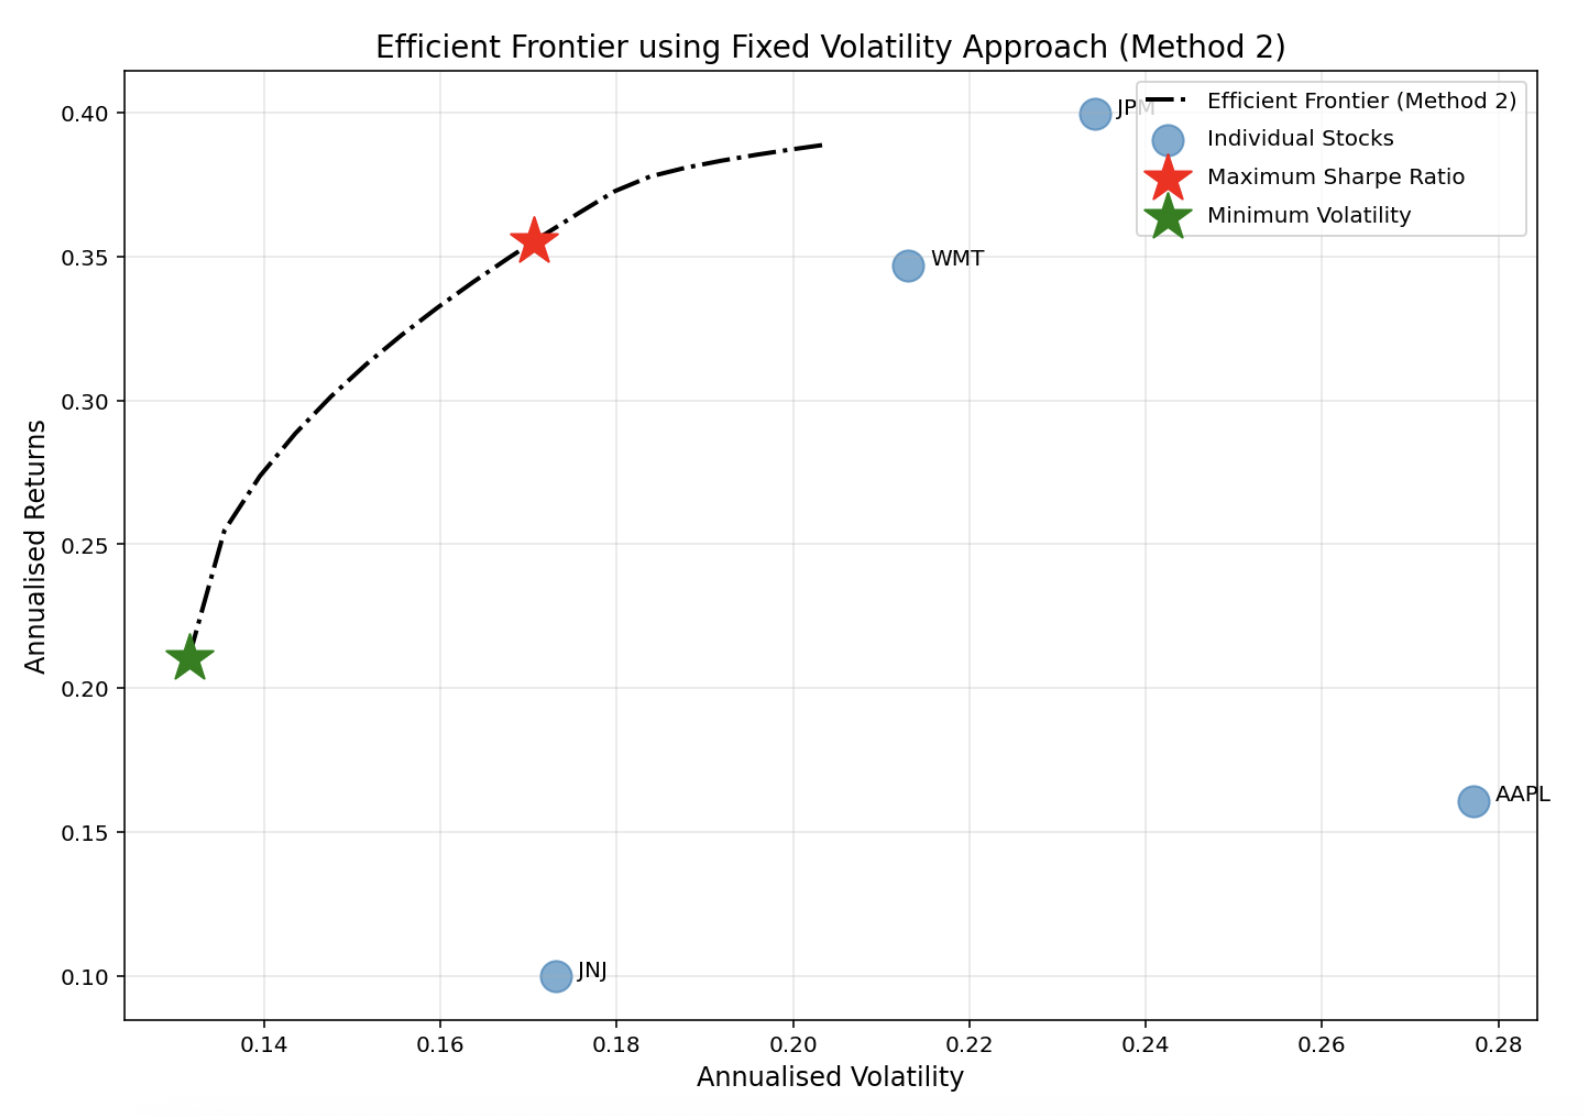

## Discussion Questions

### 1. Visual Comparison

**Question:** Compare your efficient frontier (fixed volatility approach) with the one from class (fixed return approach). Do they look the same?

**Answer:**

[Your answer here]

### 2. Mathematical Formulation

**Question:** Write down both optimization problems.

**Traditional Approach (Method 1 - from class):**

[Your answer here]

---

**Alternative Approach (Method 2 - this lab):**

[Your answer here]

---


## Summary

In this lab, you implemented an alternative approach to constructing the efficient frontier:

1. **Method 2**: Fixed volatility approach
   - For each target volatility, maximize return
   - Demonstrates the duality principle in optimization

2. **Key Learning**: Both methods produce identical efficient frontiers
   - Same optimal portfolios, different computational paths
   - Validates the uniqueness of the efficient frontier in MPT

3. **Practical Application**: Choose the method based on your constraints
   - Risk-constrained investors: Use Method 2
   - Return-targeted investors: Use Method 1

This equivalence is a fundamental result in portfolio theory and demonstrates the elegance of Markowitz's Modern Portfolio Theory framework.